---

# Support Vector Machine: Pembatalan Pesanan Ronaldo Hotel

*SVM from scratch dengan kernel linear, polynomial, dan Gaussian, beserta perbandingannya dengan scikit-learn.*

---

## Kelompok G04: TreeIsAllYouNeed

---

## Daftar Isi

1. [**Pendahuluan**](#1)
2. [**Inisialisasi**](#2)
3. [**Persiapan Data**](#3)
4. [**Pemilihan Hyperparameter**](#4)
5. [**Perbandingan dengan scikit-learn**](#5)
6. [**Model Akhir**](#6)
7. [**Bonus: Cost-Sensitive Classification**](#7)
8. [**Bonus: Bidang Pemisah, Margin, dan Support Vector**](#8)
9. [**Submission Kaggle**](#9)
10. [**Kesimpulan**](#10)
11. [**Referensi**](#11)

---

# Pendahuluan <a name="1"></a>

---

Notebook ini menguji class `SVM` di `src/algoritma/svm/svm.py`. Tiga kernel wajib (linear, polynomial, dan
Gaussian) dibandingkan dengan `sklearn.svm.SVC` pada data dan hyperparameter yang sama. Kernel Laplacian, yang
dipakai untuk submission Kaggle, ikut dibandingkan.

| Model submission | Skor publik Kaggle | Macro F1, CV 5-fold |
|---|---|---|
| SVM kernel Laplacian + bobot fitur | 0,87464 | 0,8703 (7 seed), 0,8699 (4 seed konfirmasi) |

CV 5-fold itu dijalankan terpisah dengan implementasi SMO yang setara (toleransi 0,01). Fitur dan bobot fiturnya
dihitung ulang di dalam tiap fold.

Metrik utamanya Macro F1, sesuai kompetisi. Data latih dibagi 80% data pengembangan dan 20% data uji internal
(hold-out). Hyperparameter hanya dipilih dari data pengembangan.

---

# Inisialisasi <a name="2"></a>

---

Pustaka scikit-learn hanya dipakai sebagai pembanding, untuk membagi data, dan untuk menghitung metrik.

In [1]:
import sys
import time
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.metrics import accuracy_score, confusion_matrix, f1_score, precision_score, recall_score
from sklearn.metrics.pairwise import laplacian_kernel
from sklearn.model_selection import StratifiedKFold, train_test_split
from sklearn.svm import SVC

REPO = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / "src" / "kaggle" / "dataset" / "train.csv").exists())
for folder in ("algoritma/svm", "kaggle"):
    sys.path.insert(0, str(REPO / "src" / folder))

from booking_features import build_features, clean, feature_weights, load_data, standardize
from svm import SVM

In [2]:
SEED = 42
FOLDS = 3
TUNE_ROWS = 3000
COMPARE_ROWS = 6000
SCALE = 20.0
NEG_COLOR, POS_COLOR, MUTED = "#2a78d6", "#eb6834", "#52514e"

DATA = REPO / "src" / "kaggle" / "dataset"
OUTPUT = REPO / "output" / "svm"
OUTPUT.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})


def macro_f1(y_true, y_pred):
    return f1_score(y_true, y_pred, average="macro")


def sample_rows(n, size, seed):
    return np.sort(np.random.default_rng(seed).choice(n, min(size, n), replace=False))

---

# Persiapan Data <a name="3"></a>

---

Duplikat dibuang, nilai kosong diisi median atau modus disertai penanda kosong, dan kategori di-one-hot.
Fitur tambahan terdiri atas tanggal booking, lama menginap, dan fitur saudara, yaitu rata-rata label booking lain
yang kemungkinan satu rombongan. Saudara harus memiliki tanggal datang, jumlah malam, dan kanal yang sama persis,
selisih lead time paling banyak 10 hari, selisih harga paling banyak 5%, serta kolom lunak yang sama atau kosong.

SVM peka terhadap skala, sehingga semua fitur distandardisasi. Semua statistik dihitung dari data latih di tiap
pembagian. Fitur saudara memakai label, sehingga dihitung out-of-fold untuk data latih dan dihitung ulang di tiap
pembagian.

In [3]:
train_raw, test = load_data(DATA)
train = clean(train_raw)
y_all = train["is_canceled"].to_numpy()
dev_idx, hold_idx = train_test_split(np.arange(len(train)), test_size=0.2, stratify=y_all, random_state=SEED)


def prepare(fit_idx, other_idx):
    A, B = build_features(train.iloc[fit_idx], y_all[fit_idx], train.iloc[other_idx], shared_neighbours=True)
    A, B, names = standardize(A, B)
    return A, B, names, feature_weights(A, y_all[fit_idx], SCALE)


X_dev, X_hold, names, weights = prepare(dev_idx, hold_idx)
y_dev, y_hold = y_all[dev_idx], y_all[hold_idx]
folds = [(dev_idx[a], dev_idx[b])
         for a, b in StratifiedKFold(FOLDS, shuffle=True, random_state=SEED).split(dev_idx, y_dev)]
fold_data = [prepare(a, b) for a, b in folds]
print("pengembangan:", X_dev.shape, " hold-out:", X_hold.shape, " rasio batal:", round(y_dev.mean(), 4))

pengembangan: (21847, 46)  hold-out: (5462, 46)  rasio batal: 0.3275


## Feature Selection dan Dimensionality Reduction

Seleksi fitur dilakukan lewat bobot fitur (AGOP diagonal), yang mengecilkan fitur tak berpengaruh. Reduksi
dimensi diuji dengan PCA. Keduanya dibandingkan pada bagian berikutnya.

In [4]:
def pca(A, B, keep=0.95):
    mean = A.mean(axis=0)
    _, s, components = np.linalg.svd(A - mean, full_matrices=False)
    ratio = np.cumsum(s ** 2) / np.sum(s ** 2)
    k = int(np.searchsorted(ratio, keep)) + 1
    return (A - mean) @ components[:k].T, (B - mean) @ components[:k].T


print("komponen PCA untuk 95% variansi:", pca(X_dev, X_hold)[0].shape[1], "dari", X_dev.shape[1], "fitur")
pd.Series(weights, index=names).sort_values(ascending=False).head(10).rename("bobot").to_frame().T

komponen PCA untuk 95% variansi: 33 dari 46 fitur


,sib_te,days_before_arrival,nightly_rate_idr,book_ord,arr_ord,special_requests,arrival_day,sib_n,arrival_month,booking_channel_Online Travel Agent
bobot,3.484,2.704,2.262,2.127,1.862,1.524,1.289,1.156,1.125,0.804


---

# Pemilihan Hyperparameter <a name="4"></a>

---

Tiap kombinasi dinilai dengan CV 3-fold pada data pengembangan memakai SVM from scratch. Agar cepat, SVM
dilatih dengan 3.000 baris dari tiap fold dan dinilai pada seluruh fold validasi.

In [5]:
KERNELS = {
    "Linear": dict(kernel="linear"),
    "Polynomial": dict(kernel="poly", degree=3, gamma="scale", coef0=1.0),
    "Gaussian": dict(kernel="rbf", gamma="scale"),
    "Gaussian + PCA": dict(kernel="rbf", gamma="scale"),
    "Laplacian": dict(kernel="laplacian", gamma=1 / SCALE),
    "Laplacian + bobot fitur": dict(kernel="laplacian", gamma=1 / SCALE),
}
C_VALUES = [0.1, 0.5, 2.0, 8.0]


def inputs(name, A, B, w):
    if name.endswith("PCA"):
        return pca(A, B)
    return (A * w, B * w) if name.endswith("bobot fitur") else (A, B)


rows = []
for name, params in KERNELS.items():
    started = time.time()
    data = []
    for (a, b), (A, B, _, w) in zip(folds, fold_data):
        pick = sample_rows(len(a), TUNE_ROWS, SEED)
        A, B = inputs(name, A, B, w)
        data.append((A[pick], y_all[a][pick], B, y_all[b]))
    for C in C_VALUES:
        scores = [macro_f1(yb, SVM(C=C, tol=1e-2, **params).fit(A, ya).predict(B)) for A, ya, B, yb in data]
        rows.append({"kernel": name, "C": C, "macro_f1": np.mean(scores), "std": np.std(scores)})
    print(f"{name}: {time.time() - started:.0f} detik", flush=True)
tuning = pd.DataFrame(rows)
tuning.to_csv(OUTPUT / "svm_tuning.csv", index=False)
best = tuning.loc[tuning.groupby("kernel")["macro_f1"].idxmax()].set_index("kernel").loc[list(KERNELS)]
display(tuning.pivot(index="kernel", columns="C", values="macro_f1").loc[list(KERNELS)].round(4))
best.round(4)

Linear: 79 detik


Polynomial: 12 detik


Gaussian: 5 detik


Gaussian + PCA: 5 detik


Laplacian: 35 detik


Laplacian + bobot fitur: 26 detik


C,0.1,0.5,2.0,8.0
kernel,,,,
Linear,0.8220,0.8232,0.8234,0.8235
Polynomial,0.8071,0.8178,0.8158,0.8052
Gaussian,0.7000,0.8009,0.8161,0.8120
Gaussian + PCA,0.7016,0.7979,0.8144,0.8124
Laplacian,0.7235,0.8174,0.8384,0.8292
Laplacian + bobot fitur,0.7828,0.8411,0.8499,0.8384


,C,macro_f1,std
kernel,,,
Linear,8.0,0.8235,0.0036
Polynomial,0.5,0.8178,0.0016
Gaussian,2.0,0.8161,0.0045
Gaussian + PCA,2.0,0.8144,0.0049
Laplacian,2.0,0.8384,0.0048
Laplacian + bobot fitur,2.0,0.8499,0.0028


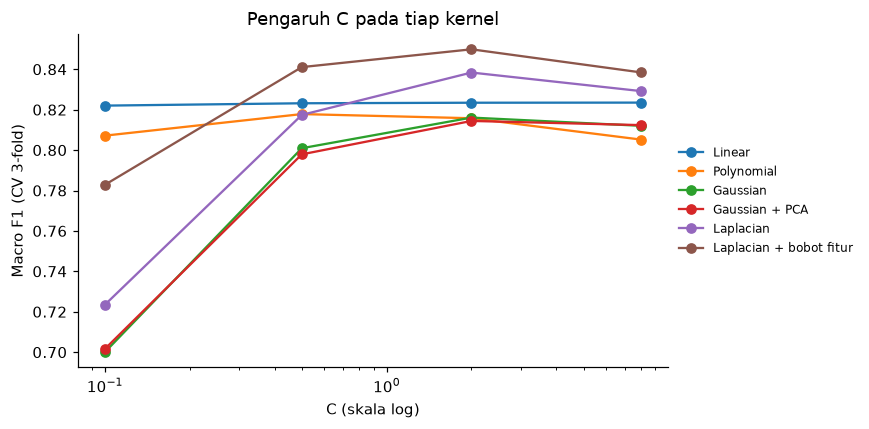

In [6]:
fig, ax = plt.subplots(figsize=(8, 4))
for k, name in enumerate(KERNELS):
    part = tuning[tuning["kernel"] == name]
    ax.plot(part["C"], part["macro_f1"], marker="o", label=name, color=plt.get_cmap("tab10")(k))
ax.set_xscale("log")
ax.set_xlabel("C (skala log)")
ax.set_ylabel("Macro F1 (CV 3-fold)")
ax.set_title("Pengaruh C pada tiap kernel")
ax.legend(frameon=False, fontsize=8, loc="center left", bbox_to_anchor=(1, 0.5))
fig.tight_layout()
fig.savefig(OUTPUT / "svm_tuning.png", bbox_inches="tight")
plt.show()

#### Insights

> Kernel Laplacian unggul di semua C mulai 0,5, dan bobot fitur menaikkannya lagi (0,8384 menjadi 0,8499 pada C = 2).
> Gaussian memakai jarak L2, sehingga satu fitur yang berbeda jauh mendominasi jarak. Jarak L1 menjumlahkan selisih
> per fitur, sehingga lebih tahan terhadap hal itu.

> Kernel linear hampir tidak peka terhadap C. Polynomial, Gaussian, dan Laplacian turun lagi pada C = 8, tanda mulai
> overfit. PCA tidak menaikkan skor Gaussian, sehingga tidak dipakai.

---

# Perbandingan dengan scikit-learn <a name="5"></a>

---

Kedua implementasi dilatih pada 6.000 baris pengembangan yang sama dengan hyperparameter terbaik, lalu
dinilai pada hold-out. Batas 6.000 baris dipakai karena kernel Laplacian di scikit-learn harus menyimpan seluruh
matriks kernel. Toleransi keduanya 0,001.

In [7]:
def sklearn_model(name, C, params):
    params = dict(params)
    if params["kernel"] == "laplacian":
        gamma = params["gamma"]
        params = dict(kernel=lambda A, B: laplacian_kernel(A, B, gamma=gamma))
    return SVC(C=C, tol=1e-3, cache_size=500, **params)


def evaluate(model, A, ya, B):
    started = time.time()
    model.fit(A, ya)
    seconds = time.time() - started
    scores = model.decision_function(B)
    return scores, (scores > 0).astype(int), seconds


pick = sample_rows(len(dev_idx), COMPARE_ROWS, SEED)
rows, kept = [], {}
for name, params in KERNELS.items():
    A, B = inputs(name, X_dev, X_hold, weights)
    C = best.loc[name, "C"]
    ours = SVM(C=C, tol=1e-3, **params)
    reference = sklearn_model(name, C, params)
    f_ours, p_ours, t_ours = evaluate(ours, A[pick], y_dev[pick], B)
    f_ref, p_ref, t_ref = evaluate(reference, A[pick], y_dev[pick], B)
    kept[name] = (f_ours, f_ref)
    for source, p, t, n_sv in (("from scratch", p_ours, t_ours, len(ours.support_)),
                               ("scikit-learn", p_ref, t_ref, len(reference.support_))):
        rows.append({"kernel": name, "C": C, "implementasi": source, "macro_f1": macro_f1(y_hold, p),
                     "akurasi": accuracy_score(y_hold, p), "presisi_batal": precision_score(y_hold, p),
                     "recall_batal": recall_score(y_hold, p), "support_vector": n_sv, "detik": t,
                     "label_sama": (p_ours == p_ref).mean(), "selisih_keputusan_maks": np.abs(f_ours - f_ref).max()})
comparison = pd.DataFrame(rows)
comparison.to_csv(OUTPUT / "svm_comparison.csv", index=False)
comparison.round(4)

,kernel,C,implementasi,macro_f1,akurasi,presisi_batal,recall_batal,support_vector,detik,label_sama,selisih_keputusan_maks
0,Linear,8.0,from scratch,0.8235,0.8510,0.8209,0.6970,2094,164.3706,0.9993,0.0176
1,Linear,8.0,scikit-learn,0.8232,0.8506,0.8199,0.6970,2095,3.9852,0.9993,0.0176
2,Polynomial,0.5,from scratch,0.8251,0.8519,0.8194,0.7026,2193,2.5537,1.0000,0.0007
3,Polynomial,0.5,scikit-learn,0.8251,0.8519,0.8194,0.7026,2193,0.7809,1.0000,0.0007
4,Gaussian,2.0,from scratch,0.8244,0.8524,0.8296,0.6914,2460,0.8026,1.0000,0.0010
5,Gaussian,2.0,scikit-learn,0.8244,0.8524,0.8296,0.6914,2461,0.8219,1.0000,0.0010
6,Gaussian + PCA,2.0,from scratch,0.8224,0.8508,0.8273,0.6881,2435,0.9336,1.0000,0.0012
7,Gaussian + PCA,2.0,scikit-learn,0.8224,0.8508,0.8273,0.6881,2435,0.6157,1.0000,0.0012
8,Laplacian,2.0,from scratch,0.8488,0.8702,0.8333,0.7546,2429,1.8126,1.0000,0.0007
9,Laplacian,2.0,scikit-learn,0.8488,0.8702,0.8333,0.7546,2428,0.8384,1.0000,0.0007


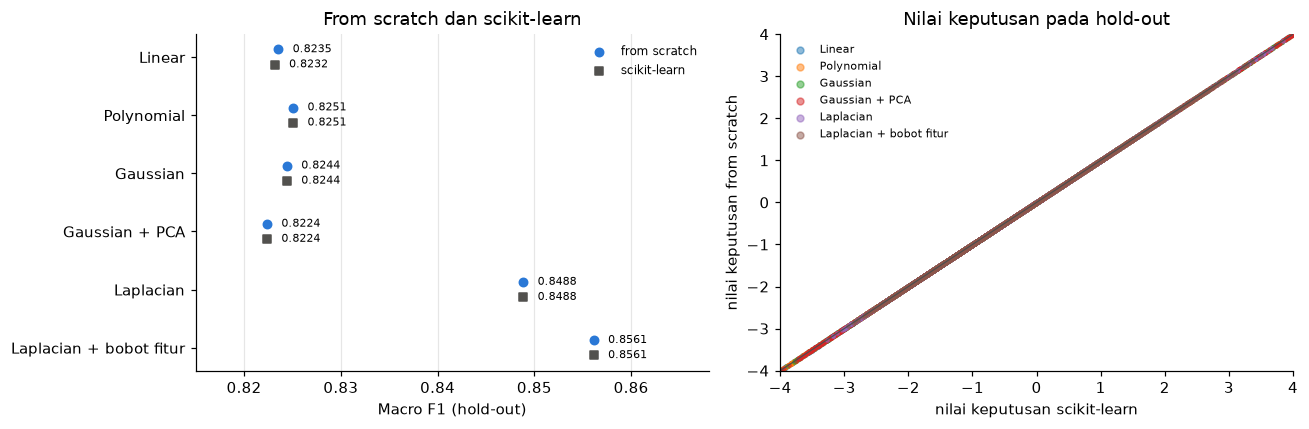

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
table = comparison.pivot(index="kernel", columns="implementasi", values="macro_f1").loc[list(KERNELS)]
pos = np.arange(len(table))
for shift, source, color, marker in ((-0.13, "from scratch", NEG_COLOR, "o"), (0.13, "scikit-learn", MUTED, "s")):
    axes[0].scatter(table[source], pos + shift, color=color, marker=marker, s=30, label=source)
    for x, y in zip(table[source], pos + shift):
        axes[0].text(x + 0.0015, y, f"{x:.4f}", fontsize=7, va="center")
axes[0].set_yticks(pos, table.index)
axes[0].invert_yaxis()
axes[0].set_xlim(0.815, 0.868)
axes[0].grid(axis="x", color="0.9")
axes[0].set_axisbelow(True)
axes[0].set_xlabel("Macro F1 (hold-out)")
axes[0].set_title("From scratch dan scikit-learn")
axes[0].legend(frameon=False, fontsize=8, loc="upper right")
for k, name in enumerate(KERNELS):
    axes[1].scatter(kept[name][1], kept[name][0], s=5, alpha=0.5, label=name, color=plt.get_cmap("tab10")(k))
axes[1].plot([-4, 4], [-4, 4], color="0.3", lw=0.8)
axes[1].set_xlim(-4, 4)
axes[1].set_ylim(-4, 4)
axes[1].set_xlabel("nilai keputusan scikit-learn")
axes[1].set_ylabel("nilai keputusan from scratch")
axes[1].set_title("Nilai keputusan pada hold-out")
axes[1].legend(frameon=False, fontsize=7, markerscale=2)
fig.tight_layout()
fig.savefig(OUTPUT / "svm_comparison.png", bbox_inches="tight")
plt.show()

#### Insights

> Implementasi from scratch setara dengan scikit-learn. Label hold-out sama persis untuk lima konfigurasi dan 99,9%
> sama untuk kernel linear. Selisih nilai keputusan terbesar sekitar 0,001, dan 0,018 pada kernel linear dengan C = 8,
> yang paling lambat konvergen. Jumlah support vector berbeda paling banyak satu.

> Perbedaannya ada di waktu. Untuk kernel linear, scikit-learn (C++ dengan shrinking) jauh lebih cepat, karena SMO
> from scratch tidak memakai shrinking dan butuh banyak iterasi. Untuk kernel lain selisihnya kecil.

---

# Model Akhir <a name="6"></a>

---

Model akhir memakai kernel Laplacian dengan bobot fitur dan C = 2, dilatih pada seluruh data pengembangan.
Nilai C ini sama dengan model submission, yang dipilih lewat CV 5-fold pada seluruh train.

50 detik, 7244 support vector
Macro F1 hold-out: 0.8649, akurasi: 0.8836


hasil save dan load identik: True


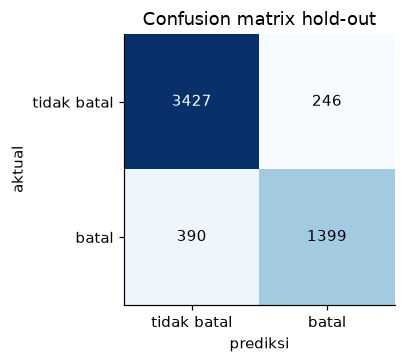

In [9]:
started = time.time()
final = SVM(kernel="laplacian", gamma=1 / SCALE, C=2.0, tol=1e-3, cache_mb=400).fit(X_dev * weights, y_dev)
f_hold = final.decision_function(X_hold * weights)
p_hold = (f_hold > 0).astype(int)
print(f"{time.time() - started:.0f} detik, {len(final.support_)} support vector")
print(f"Macro F1 hold-out: {macro_f1(y_hold, p_hold):.4f}, akurasi: {accuracy_score(y_hold, p_hold):.4f}")

path = OUTPUT / "svm_holdout_model.pkl"
final.save(path)
same = np.array_equal(SVM.load(path).decision_function(X_hold * weights), f_hold)
path.unlink()
print("hasil save dan load identik:", same)

fig, ax = plt.subplots(figsize=(3.8, 3.4))
matrix = confusion_matrix(y_hold, p_hold)
ax.imshow(matrix, cmap="Blues")
for i in range(2):
    for j in range(2):
        ax.text(j, i, matrix[i, j], ha="center", va="center",
                color="white" if matrix[i, j] > matrix.max() / 2 else "black")
ax.set_xticks([0, 1], ["tidak batal", "batal"])
ax.set_yticks([0, 1], ["tidak batal", "batal"])
ax.set_xlabel("prediksi")
ax.set_ylabel("aktual")
ax.set_title("Confusion matrix hold-out")
fig.tight_layout()
fig.savefig(OUTPUT / "svm_confusion_matrix.png", bbox_inches="tight")
plt.show()

---

# Bonus: Cost-Sensitive Classification <a name="7"></a>

---

False Positive (booking diprediksi batal padahal tidak) dianggap dua kali lebih mahal daripada False
Negative, sehingga biaya = 2 x FP + FN. Dua penanganan diuji terhadap model biasa:

1. **Geser ambang.** Ambang keputusan dipilih dari prediksi out-of-fold data pengembangan yang biayanya paling kecil.
2. **Bobot kelas.** C untuk kelas tidak batal dikali 2, sehingga kesalahan pada kelas itu dihukum lebih berat saat
   pelatihan.

Hold-out tidak dipakai untuk memilih ambang.

In [10]:
COST_FP, COST_FN = 2, 1
SETTING = dict(kernel="laplacian", gamma=1 / SCALE, C=2.0, tol=1e-2, cache_mb=400)


def errors(y_true, y_pred):
    fp = int(((y_pred == 1) & (y_true == 0)).sum())
    fn = int(((y_pred == 0) & (y_true == 1)).sum())
    return fp, fn, COST_FP * fp + COST_FN * fn


oof_scores, oof_labels = [], []
for (a, b), (A, B, _, w) in zip(folds, fold_data):
    oof_scores.append(SVM(**SETTING).fit(A * w, y_all[a]).decision_function(B * w))
    oof_labels.append(y_all[b])
oof_scores, oof_labels = np.concatenate(oof_scores), np.concatenate(oof_labels)
thresholds = np.round(np.arange(-1.0, 1.51, 0.05), 2)
oof_costs = np.array([errors(oof_labels, (oof_scores > t).astype(int))[2] for t in thresholds])
best_threshold = thresholds[oof_costs.argmin()]
print("ambang terbaik dari OOF:", best_threshold)

weighted = SVM(**SETTING, class_weight={0: float(COST_FP), 1: float(COST_FN)}).fit(X_dev * weights, y_dev)
f_weighted = weighted.decision_function(X_hold * weights)
rows = []
for label, p in (("biasa (ambang 0)", p_hold),
                 (f"geser ambang ({best_threshold})", (f_hold > best_threshold).astype(int)),
                 ("bobot kelas 2:1", (f_weighted > 0).astype(int))):
    fp, fn, cost = errors(y_hold, p)
    rows.append({"penanganan": label, "FP": fp, "FN": fn, "biaya": cost, "biaya_per_booking": cost / len(y_hold),
                 "macro_f1": macro_f1(y_hold, p), "presisi_batal": precision_score(y_hold, p),
                 "recall_batal": recall_score(y_hold, p)})
cost_table = pd.DataFrame(rows)
cost_table.to_csv(OUTPUT / "svm_cost_sensitive.csv", index=False)
cost_table.round(4)

ambang terbaik dari OOF: 0.45


,penanganan,FP,FN,biaya,biaya_per_booking,macro_f1,presisi_batal,recall_batal
0,biasa (ambang 0),246,390,882,0.1615,0.8649,0.8505,0.7820
1,geser ambang (0.45),153,505,811,0.1485,0.8553,0.8935,0.7177
2,bobot kelas 2:1,97,569,763,0.1397,0.8502,0.9263,0.6819


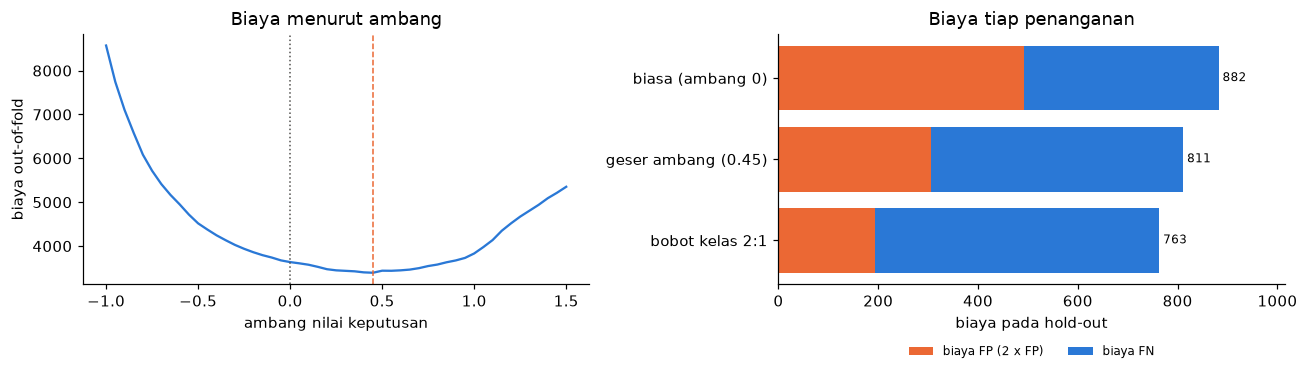

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.6))
axes[0].plot(thresholds, oof_costs, color=NEG_COLOR)
axes[0].axvline(best_threshold, color=POS_COLOR, ls="--", lw=1)
axes[0].axvline(0, color=MUTED, ls=":", lw=1)
axes[0].set_xlabel("ambang nilai keputusan")
axes[0].set_ylabel("biaya out-of-fold")
axes[0].set_title("Biaya menurut ambang")
pos = np.arange(len(cost_table))
axes[1].barh(pos, COST_FP * cost_table["FP"], color=POS_COLOR, label="biaya FP (2 x FP)")
axes[1].barh(pos, cost_table["FN"], left=COST_FP * cost_table["FP"], color=NEG_COLOR, label="biaya FN")
for i, cost in enumerate(cost_table["biaya"]):
    axes[1].text(cost + 8, i, str(cost), va="center", fontsize=8)
axes[1].set_yticks(pos, cost_table["penanganan"])
axes[1].invert_yaxis()
axes[1].set_xlim(0, cost_table["biaya"].max() * 1.15)
axes[1].set_xlabel("biaya pada hold-out")
axes[1].set_title("Biaya tiap penanganan")
axes[1].legend(frameon=False, fontsize=8, loc="upper center", bbox_to_anchor=(0.5, -0.2), ncol=2)
fig.tight_layout()
fig.savefig(OUTPUT / "svm_cost_sensitive.png", bbox_inches="tight")
plt.show()

#### Insights

> Biaya hold-out turun dari 882 menjadi 811 dengan geser ambang dan 763 dengan bobot kelas 2:1. FP turun dari 246
> menjadi 153 dan 97, dengan imbalan FN yang naik. Macro F1 ikut turun (0,8649 menjadi 0,8553 dan 0,8502), karena
> metrik itu tidak membedakan biaya kedua kesalahan.

> Bobot kelas lebih baik daripada geser ambang pada data ini. Bobot kelas mengubah bentuk bidang pemisah saat
> pelatihan, sedangkan geser ambang hanya menggeser bidang yang sama. Submission Kaggle tetap memakai model biasa,
> karena dinilai dengan Macro F1.

---

# Bonus: Bidang Pemisah, Margin, dan Support Vector <a name="8"></a>

---

Agar bisa digambar, SVM dilatih ulang hanya pada dua fitur, yaitu akar lead time dan harga per malam (keduanya
distandardisasi), dengan 250 booking dan C = 1. Garis penuh adalah bidang pemisah f(x) = 0, garis putus-putus adalah
margin f(x) = -1 dan f(x) = 1, dan lingkaran menandai support vector. Lebar margin dihitung dari 2 / ||w||, dengan
||w|| dihitung lewat koefisien dual dan matriks kernel.

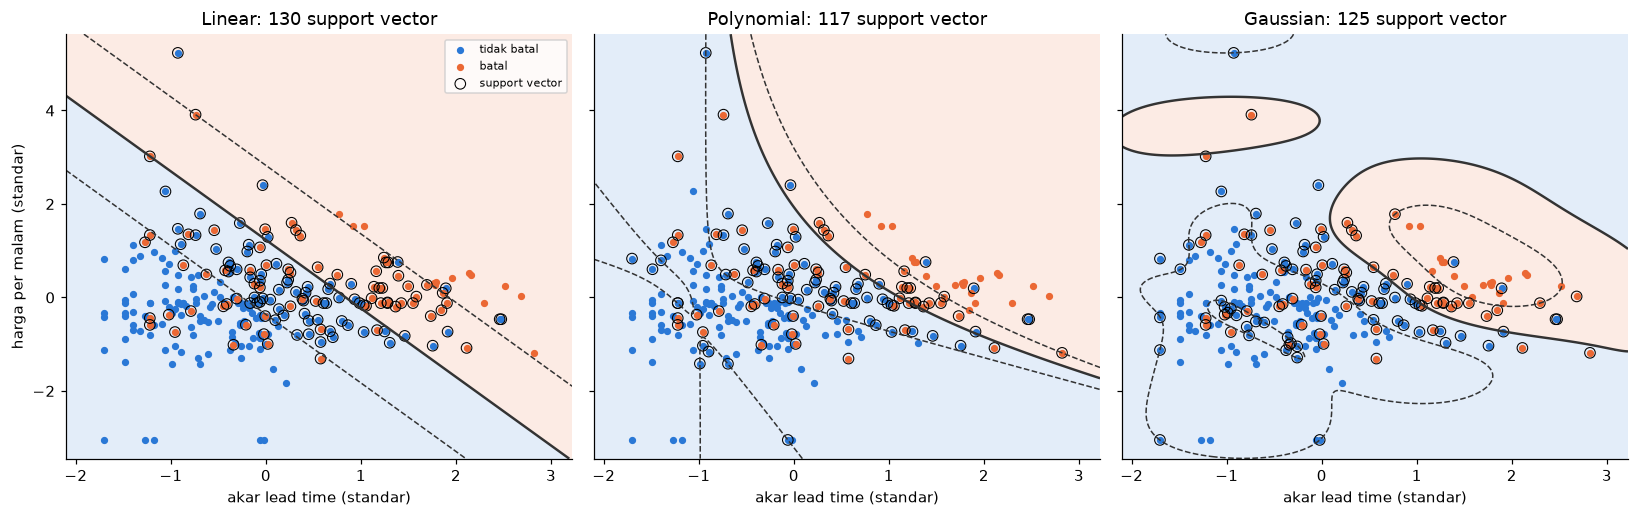

,kernel,support_vector,lebar_margin,akurasi_latih
0,Linear,130,1.7968,0.804
1,Polynomial,117,2.0145,0.808
2,Gaussian,125,0.5460,0.828


In [12]:
pair = [names.index("days_before_arrival"), names.index("nightly_rate_idr")]
points = sample_rows(len(dev_idx), 250, 7)
X2, y2 = X_dev[points][:, pair], y_dev[points]
lo, hi = X2.min(axis=0) - 0.4, X2.max(axis=0) + 0.4
gx, gy = np.meshgrid(np.linspace(lo[0], hi[0], 220), np.linspace(lo[1], hi[1], 220))
grid = np.column_stack([gx.ravel(), gy.ravel()])

fig, axes = plt.subplots(1, 3, figsize=(15, 4.8), sharex=True, sharey=True)
margins = []
for ax, name in zip(axes, ("Linear", "Polynomial", "Gaussian")):
    model = SVM(C=1.0, tol=1e-3, **KERNELS[name]).fit(X2, y2)
    f = model.decision_function(grid).reshape(gx.shape)
    ax.contourf(gx, gy, f, levels=[f.min() - 1, 0, f.max() + 1], colors=[NEG_COLOR, POS_COLOR], alpha=0.13)
    ax.contour(gx, gy, f, levels=[-1, 0, 1], colors="0.2", linestyles=["--", "-", "--"], linewidths=[1, 1.6, 1])
    for label, color, text in ((0, NEG_COLOR, "tidak batal"), (1, POS_COLOR, "batal")):
        ax.scatter(*X2[y2 == label].T, s=14, color=color, label=text)
    ax.scatter(*model.support_vectors_.T, s=48, facecolors="none", edgecolors="black", linewidths=0.7,
               label="support vector")
    f_sv = model.decision_function(model.support_vectors_) - model.intercept_
    width = 2 / np.sqrt(model.dual_coef_ @ f_sv)
    margins.append({"kernel": name, "support_vector": len(model.support_), "lebar_margin": width,
                    "akurasi_latih": (model.predict(X2) == y2).mean()})
    ax.set_title(f"{name}: {len(model.support_)} support vector")
    ax.set_xlabel("akar lead time (standar)")
axes[0].set_ylabel("harga per malam (standar)")
axes[0].legend(frameon=True, fontsize=7, loc="upper right")
fig.tight_layout()
fig.savefig(OUTPUT / "svm_decision_boundary.png", bbox_inches="tight")
plt.show()
pd.DataFrame(margins).round(4)

#### Insights

> Kernel linear menghasilkan garis lurus dengan dua margin sejajar. Polynomial membengkokkan bidang itu, dan Gaussian
> membentuk daerah batal yang tertutup. Booking dengan lead time panjang dan harga tinggi cenderung batal.

> Kedua kelas saling tumpang tindih pada dua fitur ini, sehingga sekitar separuh titik menjadi support vector. Daerah
> kecil di kiri atas pada Gaussian hanya ditopang sedikit titik, contoh risiko overfit kernel yang fleksibel. Lebar
> margin antarkernel diukur di ruang fitur masing-masing, sehingga tidak bisa dibandingkan langsung.

---

# Submission Kaggle <a name="9"></a>

---

Model submission dilatih ulang pada seluruh train. Fitur, skala, dan bobot fitur dihitung dari train, lalu
diterapkan ke test. Model disimpan, dimuat kembali, dan model hasil muat itulah yang dipakai untuk prediksi.

In [13]:
A, B = build_features(train, y_all, test, shared_neighbours=True)
A, B, _ = standardize(A, B)
w = feature_weights(A, y_all, SCALE)
started = time.time()
svm = SVM(kernel="laplacian", gamma=1 / SCALE, C=2.0, tol=1e-3, cache_mb=400).fit(A * w, y_all)
print(f"iterasi SMO: {svm.n_iter_}, support vector: {len(svm.support_)}, {time.time() - started:.0f} detik")

svm.save(OUTPUT / "svm_model.pkl")
svm = SVM.load(OUTPUT / "svm_model.pkl")

submission = pd.DataFrame({"id": test["id"], "is_canceled": svm.predict(B * w)})
sample = pd.read_csv(DATA / "sample_submission.csv", dtype={"id": str})
assert list(submission.columns) == list(sample.columns)
assert submission["id"].tolist() == sample["id"].tolist()
submission.to_csv(OUTPUT / "submission.csv", index=False)
print("baris:", len(submission), " rasio batal:", round(submission["is_canceled"].mean(), 4))

iterasi SMO: 22302, support vector: 8662, 257 detik


baris: 6844  rasio batal: 0.2984


---

# Kesimpulan <a name="10"></a>

---

- SVM from scratch dengan kernel linear, polynomial, dan Gaussian setara dengan scikit-learn pada data yang sama.
- Kernel Laplacian dengan bobot fitur paling baik, yaitu 0,8561 pada hold-out dengan 6.000 baris latih dan 0,8649
  dengan seluruh data pengembangan. Kernel wajib terbaik mencapai 0,8251.
- Untuk biaya FP dua kali FN, bobot kelas 2:1 menurunkan biaya hold-out dari 882 menjadi 763.

---

# Referensi <a name="11"></a>

---

Materi kuliah: salindia Support Vector Machines, IF3170, 2026. Metode di luar materi kuliah:

1. J. Platt, "Sequential Minimal Optimization", MSR-TR-98-14, 1998.
2. R.-E. Fan, P.-H. Chen, dan C.-J. Lin, "Working Set Selection Using Second Order Information for Training
   Support Vector Machines", JMLR 6, 2005.
3. C.-C. Chang dan C.-J. Lin, "LIBSVM: A Library for Support Vector Machines", ACM TIST 2(3), 2011 (cache kernel,
   bobot kelas, bias).
4. O. Chapelle, P. Haffner, dan V. Vapnik, "Support Vector Machines for Histogram-Based Image Classification",
   IEEE Transactions on Neural Networks 10, 1999 (kernel Laplacian).
5. A. Radhakrishnan dkk., "Mechanism for feature learning in neural networks and backpropagation-free machine
   learning models", Science, 2024, doi:10.1126/science.adi5639 (bobot fitur).
6. C. Elkan, "The Foundations of Cost-Sensitive Learning", IJCAI 2001.
7. scikit-learn, `sklearn.svm.SVC`.